<a href="https://colab.research.google.com/github/SofiaBarbas/Satellite-Orbit-Explorer/blob/main/Satellite_Orbit_Explorer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Satellite Orbit Explorer · Space Career Week 2026 · GNSS Academy

- Sofía Barbás

Este notebook contiene la implementación completa y ordenada del simulador en 8 etapas consecutivas:

1. **Stage 1**: Configuración del entorno de trabajo.
2. **Stage 2**: Carga de datos OMM JSON.
3. **Stage 3**: Conversión a parámetros Keplerianos físicos.
4. **Stage 4**: Definición de la grilla de tiempo unificada.
5. **Stage 5**: Propagación analítica (Dos cuerpos con rotación terrestre).
6. **Stage 6**: Extracción de resúmenes de telemetría.
7. **Stage 7**: Visualización 2D de ground tracks y velocidades.
8. **Stage 8**: Exportación KML para Google Earth y reporte analítico final.

### Análisis de Trayectorias Terrestres (Ground Tracks) y Velocidades

El gráfico de trayectorias en 2D proyecta las órbitas tridimensionales sobre un mapa plano, mostrando patrones distintivos según la clase de misión de cada satélite:

* **PULSAR-0 (LEO - azul):** Completa muchas pasadas rápidas. Debido a que su período ($1.58\text{ h}$) es mucho más corto que la rotación de la Tierra, la trayectoria terrestre se desplaza constantemente hacia el oeste con cada pasada sucesiva.
* **GSAT0225 (Galileo 29) (MEO - naranja):** Completa casi $1.7$ órbitas en 24 horas, generando un perfil ondulado y sinusoidal amplio que se extiende hasta $55^\circ$ de latitud, reflejando su movimiento relativo más lento sobre la Tierra.
* **SES-5 (GEO - verde):** Aparece como un único punto estático bloqueado con precisión cerca del ecuador en los $5.0^\circ\text{ E}$, debido a que su período orbital es exactamente igual al período de rotación de la Tierra.
* **QZS-2 (MICHIBIKI-2) (IGSO - rojo):** Comparte un período similar de 24 horas pero está inclinado a $39.3^\circ$ y es ligeramente excéntrico ($e=0.07$). Esto hace que trace una curva en forma de ocho asimétrica y alargada (analema) centrada sobre Japón y Australia. El lazo norte es más ancho y lento porque el satélite pasa más tiempo cerca de su apogeo.

### Mecánica de Velocidad Vis-Viva

En órbitas excéntricas (como la de **QZS-2**), la Segunda Ley de Kepler dicta que el satélite barre áreas iguales en tiempos iguales. Termodinámicamente, la energía potencial gravitatoria se convierte en energía cinética. De acuerdo con la ecuación vis-viva:
$$v = \sqrt{\mu \left(\frac{2}{r} - \frac{1}{a}\right)}$$
A medida que el satélite se aproxima al **perigeo** (punto más cercano), su distancia geocéntrica $r$ se reduce al mínimo, lo que maximiza el término $\frac{2}{r}$ y aumenta la velocidad cinética $v$. Por el contrario, en el **apogeo**, $r$ alcanza su valor máximo, disminuyendo la velocidad.

In [138]:
print('--- Stage 1: Setup - Imports, Constants, Directories and Configurations ---')
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import requests

# 1. Constants
MU_EARTH_KM3_S2 = 398600.4418
EARTH_RADIUS_KM = 6378.137

# 2. Workspace Directories
BASE_DIR = Path('/content/satellite_orbits')
IN_DIR = BASE_DIR / 'inputs'
OUT_DIR = BASE_DIR / 'outputs'

IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

STEP_SECONDS = 5
DURATION_HOURS = 24

print(f'Input directory: {IN_DIR}')
print(f'Output directory: {OUT_DIR}')
print(f'Muestreo: {STEP_SECONDS} s | Duración: {DURATION_HOURS} horas')

--- Stage 1: Setup - Imports, Constants, Directories and Configurations ---
Input directory: /content/satellite_orbits/inputs
Output directory: /content/satellite_orbits/outputs
Muestreo: 5 s | Duración: 24 horas


In [139]:
print('--- Stage 1: Setup (Updated with LIVE_GROUP) ---')
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import requests

# 1. Constants
MU_EARTH_KM3_S2 = 398600.4418
EARTH_RADIUS_KM = 6378.137

# 2. Workspace Directories
BASE_DIR = Path('/content/satellite_orbits')
IN_DIR = BASE_DIR / 'inputs'
OUT_DIR = BASE_DIR / 'outputs'

IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

STEP_SECONDS = 5
DURATION_HOURS = 24

# Opcional: Cambiar por el nombre del grupo para habilitar datos en vivo de CelesTrak
LIVE_GROUP = None

print(f'Input directory: {IN_DIR}')
print(f'Output directory: {OUT_DIR}')
print(f'Muestreo: {STEP_SECONDS} s | Duración: {DURATION_HOURS} horas')
print(f'LIVE_GROUP inicializado en: {LIVE_GROUP}')

--- Stage 1: Setup (Updated with LIVE_GROUP) ---
Input directory: /content/satellite_orbits/inputs
Output directory: /content/satellite_orbits/outputs
Muestreo: 5 s | Duración: 24 horas
LIVE_GROUP inicializado en: None


In [140]:
print('--- Stage 2: Load GP JSON - Data Ingestion & Extraction ---')
import time
import json
import zipfile
from pathlib import Path

def extract_inputs():
    required_files = ['orbital_elements.json', 'data_manifest.json', 'world_map.txt']
    all_exist = all((IN_DIR / f).is_file() for f in required_files)
    if all_exist:
        print('Todos los archivos de entrada ya están presentes.')
        return
    colab_dir = Path('/content')
    zip_files = list(colab_dir.glob('orbit_workshop_inputs*.zip'))
    if not zip_files:
        raise FileNotFoundError("Por favor sube 'orbit_workshop_inputs.zip' al entorno de Colab.")
    zip_path = zip_files[0]
    print(f'Extrayendo {zip_path.name} en {IN_DIR}...')
    with zipfile.ZipFile(zip_path, 'r') as ref:
        for member in ref.namelist():
            name = Path(member).name
            if name in required_files:
                with open(IN_DIR / name, 'wb') as out_f:
                    out_f.write(ref.read(member))
    print('Extracción completa.')

def read_gp_json(path):
    with open(path, 'r') as f:
        data = json.load(f)
    return data

extract_inputs()
sats = read_gp_json(IN_DIR / 'orbital_elements.json')
with open(IN_DIR / 'data_manifest.json', 'r') as f:
    data_manifest = json.load(f)

source_note = f'Datos de CelesTrak recuperados el: {data_manifest["retrieved_utc"]}'
print(f'{source_note}\nSatélites cargados: {len(sats)}')

--- Stage 2: Load GP JSON - Data Ingestion & Extraction ---
Todos los archivos de entrada ya están presentes.
Datos de CelesTrak recuperados el: 2026-11-10T16:30:32Z
Satélites cargados: 4


In [141]:
print('--- Stage 2 Extension: Live CelesTrak Integration ---')
import os

if LIVE_GROUP is None:
    print('LIVE_GROUP no está configurado (None). Se utilizarán los datos locales de respaldo del taller.')
else:
    cache_path = IN_DIR / f'gp_{LIVE_GROUP}.json'
    cache_duration_hours = 2
    should_download = True

    if cache_path.is_file():
        mtime = datetime.fromtimestamp(cache_path.stat().st_mtime, tz=timezone.utc)
        age = datetime.now(timezone.utc) - mtime
        if age < timedelta(hours=cache_duration_hours):
            print(f'La caché para {LIVE_GROUP} tiene {age.total_seconds()/60:.1f} minutos de antigüedad (umbral: {cache_duration_hours}h). Cargando desde caché.')
            should_download = False

    if should_download:
        url = f'https://celestrak.org/NORAD/elements/gp.php?GROUP={LIVE_GROUP}&FORMAT=JSON'
        print(f'Descargando datos en vivo de CelesTrak para {LIVE_GROUP} de {url}...')
        try:
            res = requests.get(url, timeout=30)
            res.raise_for_status()
            live_data = res.json()
            if not isinstance(live_data, list) or len(live_data) == 0:
                raise ValueError('La respuesta de CelesTrak no contiene registros válidos.')

            with open(cache_path, 'w') as f:
                json.dump(live_data, f)
            print(f'Datos en vivo guardados exitosamente en {cache_path}.')
        except Exception as e:
            print(f'Error en la descarga: {e}. Reintentando usar caché de respaldo...')
            if cache_path.is_file():
                print('Se recuperó la caché antigua debido al error de red.')
            else:
                raise e

    # Cargar datos desde la caché
    with open(cache_path, 'r') as f:
        raw_sats = json.load(f)

    # Filtrar y ordenar por ID de catálogo NORAD para seleccionar los primeros 4 satélites
    sorted_sats = sorted(raw_sats, key=lambda x: int(x.get('NORAD_CAT_ID', 999999)))
    sats = sorted_sats[:4]

    # Actualizar nota de fuente
    cache_time = datetime.fromtimestamp(cache_path.stat().st_mtime, tz=timezone.utc).isoformat().replace('+00:00', 'Z')
    source_note = f'Datos en vivo de CelesTrak (Grupo: {LIVE_GROUP}) recuperados el: {cache_time}'

    print(f'\n{source_note}')
    print('Primeros 4 satélites seleccionados del grupo para la simulación:')
    for s in sats:
        print(f" - {s.get('OBJECT_NAME')} [NORAD {s.get('NORAD_CAT_ID')}]")

--- Stage 2 Extension: Live CelesTrak Integration ---
LIVE_GROUP no está configurado (None). Se utilizarán los datos locales de respaldo del taller.


### Stage 3: Parse Elements - Conversión de elementos GP JSON a parámetros físicos de Kepler

Convertimos la velocidad angular (`MEAN_MOTION`) en radianes por segundo y aplicamos la Tercera Ley de Kepler para determinar el semi-eje mayor ($a$). Los ángulos de orientación se convierten a radianes para su uso analítico.

In [142]:
print('--- Stage 3: Parse Elements ---')
def parse_gp_epoch(text):
    return datetime.fromisoformat(text.rstrip('Z')).replace(tzinfo=timezone.utc)

def parse_gp_elements(rec):
    name = rec['OBJECT_NAME']
    norad_id = int(rec['NORAD_CAT_ID'])
    epoch = parse_gp_epoch(rec['EPOCH'])
    n_rad_s = (rec['MEAN_MOTION'] * 2.0 * math.pi) / 86400.0
    a_km = (MU_EARTH_KM3_S2 / (n_rad_s ** 2)) ** (1.0 / 3.0)
    e = rec['ECCENTRICITY']
    i_rad = math.radians(rec['INCLINATION'])
    raan_rad = math.radians(rec['RA_OF_ASC_NODE'])
    argp_rad = math.radians(rec['ARG_OF_PERICENTER'])
    M0_rad = math.radians(rec['MEAN_ANOMALY'])
    return {
        'name': name, 'norad_id': norad_id, 'label': f'{name} [{norad_id}]',
        'epoch': epoch, 'n_rad_s': n_rad_s, 'a_km': a_km, 'e': e,
        'i_rad': i_rad, 'raan_rad': raan_rad, 'argp_rad': argp_rad, 'M0_rad': M0_rad
    }

elements = [parse_gp_elements(s) for s in sats]
for row in elements_table(elements):
    print(row)

--- Stage 3: Parse Elements ---
Satellite Name            | NORAD  | Epoch (UTC)                | a (km)     | e        | i (deg) | Ω (deg) | ω (deg) | M (deg)
-------------------------------------------------------------------------------------------------------------------------------
PULSAR-0                  | 64541  | 2026-11-10 04:10:34.900    | 6880.971   | 0.000408 | 97.48   | 67.63   | 54.16   | 306.00 
GSAT0225 (GALILEO 29)     | 59598  | 2026-11-09 08:30:06.579    | 29600.256  | 0.000159 | 55.22   | 97.02   | 171.21  | 226.89 
SES-5                     | 38652  | 2026-11-10 04:02:09.139    | 42164.283  | 0.000191 | 0.05    | 32.20   | 188.01  | 254.68 
QZS-2 (MICHIBIKI-2)       | 42738  | 2026-10-17 15:21:52.982    | 42170.355  | 0.074521 | 39.25   | 241.35  | 270.89  | 243.82 


### Stage 4: Time Window - Definición de la grilla temporal unificada de simulación

Establecemos un marco temporal común de 24 horas a partir de la fecha del vector de estado más reciente para sincronizar la simulación de todas las plataformas.

In [143]:
print('--- Stage 4: Time Window ---')
newest_epoch = max(el['epoch'] for el in elements)
start_utc = datetime.combine(newest_epoch.date(), datetime.min.time(), tzinfo=timezone.utc)
end_utc = start_utc + timedelta(hours=DURATION_HOURS)
total_seconds = int((end_utc - start_utc).total_seconds())
n_points = (total_seconds // STEP_SECONDS) + 1
times = [start_utc + timedelta(seconds=i * STEP_SECONDS) for i in range(n_points)]
print(f'Malla unificada iniciada en: {start_utc} hasta {end_utc}')

--- Stage 4: Time Window ---
Malla unificada iniciada en: 2026-11-10 00:00:00+00:00 hasta 2026-11-11 00:00:00+00:00


### Stage 5: Propagate - Propagación orbital analítica bajo física de dos cuerpos

Se resuelve iterativamente la ecuación trascendental de Kepler usando Newton-Raphson. Las posiciones en el plano orbital inercial son trasladadas al sistema de coordenadas de rotación terrestre (ECEF) calculando el tiempo sidéreo Greenwich (GMST).

In [144]:
print('--- Stage 5: Propagación Orbital ---')
def solve_kepler(M, e, max_iter=50, tol=1e-11):
    M = M % (2 * math.pi)
    E = math.pi if e > 0.8 else M
    for _ in range(max_iter):
        f = E - e * math.sin(E) - M
        f_prime = 1.0 - e * math.cos(E)
        delta = f / f_prime
        E -= delta
        if abs(delta) < tol: return E
    raise ValueError('Error de convergencia en Kepler')

def gmst_rad(utc_time):
    j2000_epoch = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
    d = (utc_time - j2000_epoch).total_seconds() / 86400.0
    T = d / 36525.0
    theta_deg = 280.46061837 + 360.98564736629 * d + 0.000387933 * (T ** 2)
    return math.radians(theta_deg % 360.0)

def propagate(el, times):
    results = []
    for t in times:
        dt_seconds = (t - el['epoch']).total_seconds()
        M = (el['M0_rad'] + el['n_rad_s'] * dt_seconds) % (2.0 * math.pi)
        E = solve_kepler(M, el['e'])
        r = el['a_km'] * (1.0 - el['e'] * math.cos(E))
        nu = math.atan2(math.sqrt(1.0 - el['e']**2) * math.sin(E), math.cos(E) - el['e'])
        u = el['argp_rad'] + nu
        x_eci = r * (math.cos(el['raan_rad']) * math.cos(u) - math.sin(el['raan_rad']) * math.sin(u) * math.cos(el['i_rad']))
        y_eci = r * (math.sin(el['raan_rad']) * math.cos(u) + math.cos(el['raan_rad']) * math.sin(u) * math.cos(el['i_rad']))
        z_eci = r * math.sin(u) * math.sin(el['i_rad'])
        theta = gmst_rad(t)
        x_ecef = math.cos(theta) * x_eci + math.sin(theta) * y_eci
        y_ecef = -math.sin(theta) * x_eci + math.cos(theta) * y_eci
        z_ecef = z_eci
        lat_deg = math.degrees(math.atan2(z_ecef, math.hypot(x_ecef, y_ecef)))
        lon_deg = math.degrees(math.atan2(y_ecef, x_ecef))
        lon_deg = (lon_deg + 180.0) % 360.0 - 180.0
        speed_km_s = math.sqrt(MU_EARTH_KM3_S2 * (2.0 / r - 1.0 / el['a_km']))
        results.append({'time': t, 'lat_deg': lat_deg, 'lon_deg': lon_deg, 'alt_km': r - EARTH_RADIUS_KM, 'speed_km_s': speed_km_s})
    return results

tracks = {el['norad_id']: propagate(el, times) for el in elements}
print('¡Propagación completada exitosamente!')

--- Stage 5: Propagación Orbital ---
¡Propagación completada exitosamente!


### Stage 6: Orbit Summary - Análisis de telemetría y extremos de velocidad

Extraemos los valores extremos de velocidad y altitud (apogeo y perigeo) de cada satélite integrando la ecuación *vis-viva*.

In [145]:
print('--- Stage 6: Orbit Summaries ---')
def orbit_summary(el, pts):
    period_h = (2.0 * math.pi / el['n_rad_s']) / 3600.0
    perigee_km = el['a_km'] * (1.0 - el['e']) - EARTH_RADIUS_KM
    apogee_km = el['a_km'] * (1.0 + el['e']) - EARTH_RADIUS_KM
    speeds = [pt['speed_km_s'] for pt in pts]
    return {
        'name': el['name'], 'norad_id': el['norad_id'], 'period_h': period_h,
        'perigee_km': perigee_km, 'apogee_km': apogee_km, 'e': el['e'],
        'i_deg': math.degrees(el['i_rad']), 'min_speed': min(speeds), 'max_speed': max(speeds)
    }

summaries = [orbit_summary(el, tracks[el['norad_id']]) for el in elements]
for row in summary_table(summaries):
    print(row)

--- Stage 6: Orbit Summaries ---
Satellite Name            | NORAD  | Period (h) | Perigee (km) | Apogee (km)  | e        | i (deg) | Vmin(km/s) | Vmax(km/s)
----------------------------------------------------------------------------------------------------------------------------
PULSAR-0                  | 64541  | 1.58       | 500.0        | 505.6        | 0.000408 | 97.48   | 7.608      | 7.614     
GSAT0225 (GALILEO 29)     | 59598  | 14.08      | 23217.4      | 23226.8      | 0.000159 | 55.22   | 3.669      | 3.670     
SES-5                     | 38652  | 23.93      | 35778.1      | 35794.2      | 0.000191 | 0.05    | 3.074      | 3.075     
QZS-2 (MICHIBIKI-2)       | 42738  | 23.94      | 32649.6      | 38934.8      | 0.074521 | 39.25   | 2.853      | 3.313     


### Stage 7: Plots - Visualización en 2D de Ground Tracks y Velocidades

Generamos el mapa de trayectorias sobre el globo terrestre evitando líneas fantasma de salto de longitud (+180 a -180 grados).

--- Stage 7: Plots - Generate 2D trajectory visualizations (ground tracks) ---


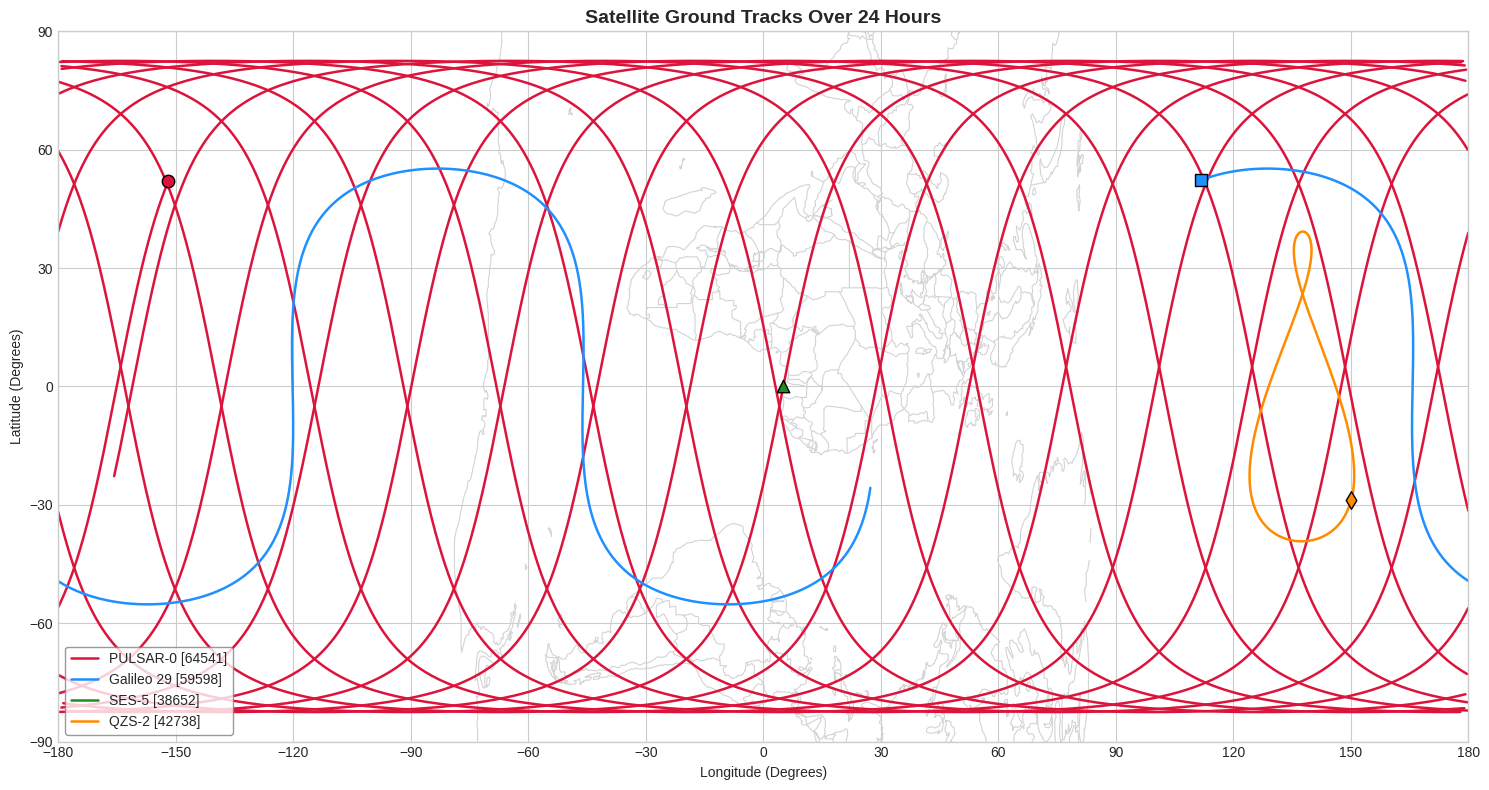

Trayectorias de satélites guardadas en: /content/satellite_orbits/outputs/ground_tracks.png


In [146]:
print('--- Stage 7: Plots - Generate 2D trajectory visualizations (ground tracks) ---')
import matplotlib.pyplot as plt
import numpy as np

def load_world_map(path):
    with open(path, 'r') as f:
        lines = f.readlines()
    map_segments = []
    current_segment = []
    for line in lines:
        line = line.strip()
        if not line or line.startswith('#'):
            if current_segment:
                map_segments.append(current_segment)
                current_segment = []
            continue
        parts = line.split()
        if len(parts) == 2:
            try:
                lon, lat = float(parts[0]), float(parts[1])
                current_segment.append((lon, lat))
            except ValueError:
                continue
    if current_segment:
        map_segments.append(current_segment)
    return map_segments

# Cargar los segmentos del mapa mundi
world_map_segments = load_world_map(IN_DIR / 'world_map.txt')

plt.figure(figsize=(15, 8))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Dibujar el mapa mundi de fondo
for segment in world_map_segments:
    seg_lons, seg_lats = zip(*segment)
    plt.plot(seg_lons, seg_lats, color='lightgray', linewidth=0.8)

# Configuración de estilos para los satélites
sat_styles = {
    64541: {'color': 'crimson', 'linestyle': '-', 'marker': 'o', 'label_prefix': 'PULSAR-0'},
    59598: {'color': 'dodgerblue', 'linestyle': '-', 'marker': 's', 'label_prefix': 'Galileo 29'},
    38652: {'color': 'forestgreen', 'linestyle': '-', 'marker': '^', 'label_prefix': 'SES-5'},
    42738: {'color': 'darkorange', 'linestyle': '-', 'marker': 'd', 'label_prefix': 'QZS-2'}
}

for el in elements:
    nid = el['norad_id']
    pts = tracks[nid]
    lons = np.array([p['lon_deg'] for p in pts])
    lats = np.array([p['lat_deg'] for p in pts])

    # Evitar las líneas que cruzan bruscamente el mapa de -180 a 180
    diffs = np.diff(lons)
    split_indices = np.where(np.abs(diffs) > 180.0)[0] + 1
    lon_splits = np.split(lons, split_indices)
    lat_splits = np.split(lats, split_indices)

    style = sat_styles.get(nid, {'color': 'purple', 'linestyle': '-', 'marker': 'x', 'label_prefix': el['name']})
    for k, (sub_lon, sub_lat) in enumerate(zip(lon_splits, lat_splits)):
        lbl = f"{style['label_prefix']} [{nid}]" if k == 0 else ""
        plt.plot(sub_lon, sub_lat, color=style['color'], linestyle=style['linestyle'], linewidth=1.8, label=lbl)
    plt.scatter(lons[0], lats[0], color=style['color'], marker=style['marker'], s=80, edgecolors='black', zorder=5)

plt.title("Satellite Ground Tracks Over 24 Hours", fontsize=14, fontweight='bold')
plt.xlabel("Longitude (Degrees)")
plt.ylabel("Latitude (Degrees)")
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.xticks(np.arange(-180, 181, 30))
plt.yticks(np.arange(-90, 91, 30))
plt.legend(loc='lower left', frameon=True, facecolor='white', edgecolor='gray')
plt.tight_layout()

output_plot_path = OUT_DIR / 'ground_tracks.png'
plt.savefig(output_plot_path, dpi=300)
plt.show()
print(f'Trayectorias de satélites guardadas en: {output_plot_path}')

### Análisis de la Visualización de Trayectorias Terrestres

Las trayectorias en 2D proyectan la órbita 3D centrada en la Tierra sobre una proyección plana de Mercator, permitiéndonos identificar y analizar visualmente las clasificaciones orbitales:

* **PULSAR-0 (LEO - Rojo):** Muestra múltiples barridos sinusoidales consecutivos de alta frecuencia que cruzan el ecuador en intervalos regulares. Debido a la rotación de la Tierra durante cada órbita rápida de $1.58\text{ h}$, cada pasada se desplaza sistemáticamente hacia el oeste.
* **GSAT0225 (Galileo 29) (MEO - Azul):** Genera una trayectoria ondulada más suave y amplia que alcanza hasta los $55^\circ$ de latitud. Al tener un período orbital de $14.08\text{ h}$, completa casi $1.7$ órbitas en 24 horas, evidenciando su menor velocidad sobre el suelo.
* **SES-5 (GEO - Verde):** Se muestra como un único punto estático fijo sobre el ecuador cerca de los $5.0^\circ\text{ E}$. Esto ilustra el acoplamiento geoestacionario perfecto entre el período del satélite y la rotación sideral terrestre.
* **QZS-2 (IGSO - Naranja):** Dibuja una curva asimétrica y alargada en **forma de ocho (analema)** centrada sobre las longitudes de Australia Oriental y Japón ($140^\circ - 150^\circ\text{ E}$). El lazo del norte es más ancho debido a que la órbita elíptica del satélite se ralentiza en el apogeo (sobre Japón) y se acelera en el perigeo (sobre los océanos del sur).

### Stage 8: KML and Report - Exportación de órbitas a Google Earth y empaquetado ZIP

Construimos los archivos KML estáticos en 3D (para órbitas espaciales) y dinámicos animados (usando `gx:MultiTrack` para Google Earth) junto al reporte analítico, comprimiendo todo en un único descargable.

In [147]:
print('--- Stage 8: Generating KML and Compiling Reports (Universal Compatibility KML) ---')
import xml.etree.ElementTree as ET
import zipfile
from pathlib import Path
from matplotlib.colors import to_hex
from google.colab import files

kml_static_path = OUT_DIR / 'orbit_tracks_ecef.kml'
kml_anim_path = OUT_DIR / 'orbit_animation.kml'
report_txt_path = OUT_DIR / 'orbit_report.txt'
zip_out_path = OUT_DIR / 'satellite_orbit_outputs.zip'

sat_colors = {
    64541: 'crimson',      # PULSAR-0
    59598: 'dodgerblue',   # Galileo 29
    38652: 'forestgreen',  # SES-5
    42738: 'darkorange'    # QZS-2
}

ET.register_namespace('', 'http://www.opengis.net/kml/2.2')

def convert_color_to_kml_hex(matplotlib_color_name):
    hex_str = to_hex(matplotlib_color_name)
    r = hex_str[1:3]
    g = hex_str[3:5]
    b = hex_str[5:7]
    return f"ff{b}{g}{r}"

def build_static_kml(elements, tracks, sat_colors, output_path):
    kml = ET.Element('kml', xmlns='http://www.opengis.net/kml/2.2')
    document = ET.SubElement(kml, 'Document')

    title = ET.SubElement(document, 'name')
    title.text = 'Multi-Satellite Orbits | Earth-fixed'

    for el in elements:
        nid = el['norad_id']
        pts = tracks[nid]
        kml_color = convert_color_to_kml_hex(sat_colors.get(nid, 'purple'))

        style = ET.SubElement(document, 'Style', id=f"style_{nid}")
        line_style = ET.SubElement(style, 'LineStyle')
        col_node = ET.SubElement(line_style, 'color')
        col_node.text = kml_color
        width = ET.SubElement(line_style, 'width')
        width.text = '3'

        placemark = ET.SubElement(document, 'Placemark')
        name_node = ET.SubElement(placemark, 'name')
        name_node.text = el['name']
        style_url = ET.SubElement(placemark, 'styleUrl')
        style_url.text = f"#style_{nid}"

        line_string = ET.SubElement(placemark, 'LineString')
        alt_mode = ET.SubElement(line_string, 'altitudeMode')
        alt_mode.text = 'absolute'

        coord_list = [f"{p['lon_deg']:.6f},{p['lat_deg']:.6f},{p['alt_km']*1000.0:.1f}" for p in pts]
        coords_node = ET.SubElement(line_string, 'coordinates')
        coords_node.text = " ".join(coord_list)

    tree = ET.ElementTree(kml)
    tree.write(output_path, encoding='utf-8', xml_declaration=True)
    print(f'Creado KML estático en: {output_path}')

def build_animated_kml(elements, tracks, sat_colors, output_path):
    kml = ET.Element('kml', xmlns='http://www.opengis.net/kml/2.2')
    document = ET.SubElement(kml, 'Document')

    title = ET.SubElement(document, 'name')
    title.text = 'Multi-Satellite Ground Tracks | Universal Animation'

    # Crear carpeta para estilos e íconos
    for el in elements:
        nid = el['norad_id']
        pts = tracks[nid]
        kml_color = convert_color_to_kml_hex(sat_colors.get(nid, 'purple'))

        # Estilo para el icono del satélite móvil
        style = ET.SubElement(document, 'Style', id=f"anim_style_{nid}")
        icon_style = ET.SubElement(style, 'IconStyle')
        icon_col = ET.SubElement(icon_style, 'color')
        icon_col.text = kml_color
        scale = ET.SubElement(icon_style, 'scale')
        scale.text = '1.2'
        icon = ET.SubElement(icon_style, 'Icon')
        href = ET.SubElement(icon, 'href')
        href.text = 'http://maps.google.com/mapfiles/kml/shapes/target.png'  # Icono de mira/satélite universal

        # Estilo para la trayectoria de fondo
        style_line = ET.SubElement(document, 'Style', id=f"line_style_{nid}")
        line_style = ET.SubElement(style_line, 'LineStyle')
        line_col = ET.SubElement(line_style, 'color')
        # Color semi-transparente para la línea de fondo
        line_col.text = f"7f{kml_color[2:]}"
        width = ET.SubElement(line_style, 'width')
        width.text = '2'

        # 1. Añadir la órbita estática completa de fondo para este satélite
        bg_placemark = ET.SubElement(document, 'Placemark')
        bg_name = ET.SubElement(bg_placemark, 'name')
        bg_name.text = f"{el['name']} (Trayectoria)"
        bg_style = ET.SubElement(bg_placemark, 'styleUrl')
        bg_style.text = f"#line_style_{nid}"
        bg_line = ET.SubElement(bg_placemark, 'LineString')
        bg_alt = ET.SubElement(bg_line, 'altitudeMode')
        bg_alt.text = 'absolute'
        bg_coords = ET.SubElement(bg_line, 'coordinates')
        bg_coords.text = " ".join([f"{p['lon_deg']:.6f},{p['lat_deg']:.6f},{p['alt_km']*1000.0:.1f}" for p in pts[::6]])

        # 2. Añadir la serie de marcas de tiempo de posición secuenciales
        # Muestreo cada 120 segundos (paso de 24 en la grilla de 5s) para mantener el archivo ágil y responsivo
        folder = ET.SubElement(document, 'Folder')
        f_name = ET.SubElement(folder, 'name')
        f_name.text = f"{el['name']} (Posición Dinámica)"

        sampled_pts = pts[::24]
        if sampled_pts[-1]['time'] != pts[-1]['time']:
            sampled_pts.append(pts[-1])

        for p in sampled_pts:
            placemark = ET.SubElement(folder, 'Placemark')

            # La etiqueta temporal TimeStamp activa de inmediato el TimeSlider en Google Earth
            time_node = ET.SubElement(placemark, 'TimeStamp')
            when = ET.SubElement(time_node, 'when')
            when.text = p['time'].strftime('%Y-%m-%dT%H:%M:%SZ')

            p_name = ET.SubElement(placemark, 'name')
            p_name.text = f"{el['name']} ({p['time'].strftime('%H:%M:%S')})"

            style_url = ET.SubElement(placemark, 'styleUrl')
            style_url.text = f"#anim_style_{nid}"

            point = ET.SubElement(placemark, 'Point')
            alt_mode = ET.SubElement(point, 'altitudeMode')
            alt_mode.text = 'absolute'
            coords = ET.SubElement(point, 'coordinates')
            # Situamos al satélite flotando a su altitud orbital real multiplicada por 1000 metros
            coords.text = f"{p['lon_deg']:.6f},{p['lat_deg']:.6f},{p['alt_km']*1000.0:.1f}"

    tree = ET.ElementTree(kml)
    tree.write(output_path, encoding='utf-8', xml_declaration=True)
    print(f'Creado KML animado universal en: {output_path}')

def generate_text_report(output_path):
    with open(output_path, 'w', encoding='utf-8') as f:
        f.write("Reporte de Simulación Orbital GNSS Academy 2026\n")
        f.write("="*80 + "\n")
        f.write(f"{source_note}\n")
        f.write(f"Inicio de ventana: {times[0].strftime('%Y-%m-%d %H:%M:%S UTC')}\n")
        f.write(f"Fin de ventana:    {times[-1].strftime('%Y-%m-%d %H:%M:%S UTC')}\n")
        f.write(f"Intervalo:         {STEP_SECONDS} s | Puntos totales: {n_points}\n\n")

        f.write("Parámetros orbitales calculados:\n")
        f.write("-"*80 + "\n")
        for s in summaries:
            f.write(f"Satélite: {s['name']} [NORAD {s['norad_id']}]\n")
            f.write(f"  - Período Orbital:  {s['period_h']:.2f} h\n")
            f.write(f"  - Apogeo / Perigeo: {s['apogee_km']:.1f} km / {s['perigee_km']:.1f} km\n")
            f.write(f"  - Velocidad (Min / Max): {s['min_speed']:.3f} km/s / {s['max_speed']:.3f} km/s\n\n")
    print(f'Reporte analítico guardado en: {output_path}')

build_static_kml(elements, tracks, sat_colors, kml_static_path)
build_animated_kml(elements, tracks, sat_colors, kml_anim_path)
generate_text_report(report_txt_path)

with zipfile.ZipFile(zip_out_path, 'w', zipfile.ZIP_DEFLATED) as zip_ref:
    for filename in ['ground_tracks.png', 'orbit_tracks_ecef.kml', 'orbit_animation.kml', 'orbit_report.txt']:
        file_to_add = OUT_DIR / filename
        if file_to_add.is_file():
            zip_ref.write(file_to_add, arcname=filename)

print(f'Proceso completado. Paquete consolidado generado en: {zip_out_path}')

# Forzar la descarga en el navegador del usuario
print('Iniciando descarga del archivo ZIP...')
files.download(str(zip_out_path))

--- Stage 8: Generating KML and Compiling Reports (Universal Compatibility KML) ---
Creado KML estático en: /content/satellite_orbits/outputs/orbit_tracks_ecef.kml
Creado KML animado universal en: /content/satellite_orbits/outputs/orbit_animation.kml
Reporte analítico guardado en: /content/satellite_orbits/outputs/orbit_report.txt
Proceso completado. Paquete consolidado generado en: /content/satellite_orbits/outputs/satellite_orbit_outputs.zip
Iniciando descarga del archivo ZIP...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 🗺️ Guía para abrir los KML en Google Earth Pro (Escritorio)

#### 1. Visualización de Órbitas 3D Estáticas (`orbit_tracks_ecef.kml`):
* Abre Google Earth Pro y selecciona **Archivo > Abrir...** para cargar `orbit_tracks_ecef.kml`.
* Verás las órbitas suspendidas en el espacio tridimensional alrededor de la Tierra, cada una con su respectiva altitud real (metros) y un color representativo idéntico al de los gráficos.

#### 2. Visualización de Animaciones Dinámicas (`orbit_animation.kml`):
* Importa `orbit_animation.kml` de la misma manera.
* Google Earth Pro detectará automáticamente las etiquetas temporales `<when>` y activará un **reproductor y deslizador de tiempo** en la esquina superior izquierda de la pantalla.
* Ajusta la velocidad de reproducción y presiona **Play (►)** para ver a los cuatro satélites avanzar de forma coordinada, respetando la física de su velocidad a lo largo de las 24 horas.